# **YOLOV11**

In [ ]:
!nvidia-smi

Wed Apr  8 17:57:34 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   39C    P8              9W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
import os
HOME = os.getcwd()
print(HOME)

/content


In [ ]:
!pip install ultralytics -q

from IPython import display
import ultralytics

display.clear_output()

!yolo settings sync=False

ultralytics.checks()

print("YOLOv11 ortamı hazır! 🚀")

Ultralytics 8.4.36 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 43.3/112.6 GB disk)
YOLOv11 ortamı hazır! 🚀


In [ ]:
from ultralytics import YOLO

from IPython.display import display, Image

In [ ]:
%cd {HOME}
!rm -rf datasets
!mkdir datasets
%cd datasets

import os
api_key = os.getenv("ROBOFLOW_API_KEY", "YOUR_ROBOFLOW_API_KEY")
dataset_id = "YOUR_DATASET_ID"
if api_key == "YOUR_ROBOFLOW_API_KEY" or dataset_id == "YOUR_DATASET_ID":
    raise ValueError("Please add your Roboflow API key and dataset id before running this cell.")
dataset_url = f"https://app.roboflow.com/ds/{dataset_id}?key={api_key}"
!curl -L "{dataset_url}" > roboflow.zip; unzip -o roboflow.zip; rm roboflow.zip

!ls -F

/content
/content/datasets
  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100   904  100   904    0     0   2871      0 --:--:-- --:--:-- --:--:--  2878
100 12.5M  100 12.5M    0     0  11.6M      0  0:00:01  0:00:01 --:--:-- 65.9M
Archive:  roboflow.zip
 extracting: train/images/1282_jpg.rf.09d29c99ffcb03af2b3ed1193ed926b3.jpg  
 extracting: train/images/0481_jpg.rf.8e482812eace35eb38eb0e9a80d7e150.jpg  
 extracting: valid/images/1737_jpg.rf.211ff6cf4da7f410f965fc6c32218ddd.jpg  
 extracting: train/images/1297_jpg.rf.148f1c2e34bde4520a9c16fcd0631757.jpg  
 extracting: train/images/1067_jpg.rf.85917ee1d7e3a42a2eb228b2c38bc686.jpg  
 extracting: train/images/1071_jpg.rf.144da6994e475c7415497eeddda8efa8.jpg  
 extracting: train/images/0785_jpg.rf.1b93267f6252f4664d3ddefc108651d1.jpg  
 extracting: train/images/0871_jpg.rf.000d9aea63914aa12630ee1641a0a65c.jpg  
 extracting: train

In [ ]:
%cd {HOME}


!yolo task=detect mode=train \
  model=yolo11s.pt \
  data={dataset.location}/data.yaml \
  epochs=25 \
  imgsz=800 \
  batch=8 \
  plots=True \
  name=yolo11_skin_cancer_project

/content
Ultralytics 8.4.36 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/datasets/Skin-Cancer-1/data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=25, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=800, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo11_skin_cancer_project3, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, ov

/content


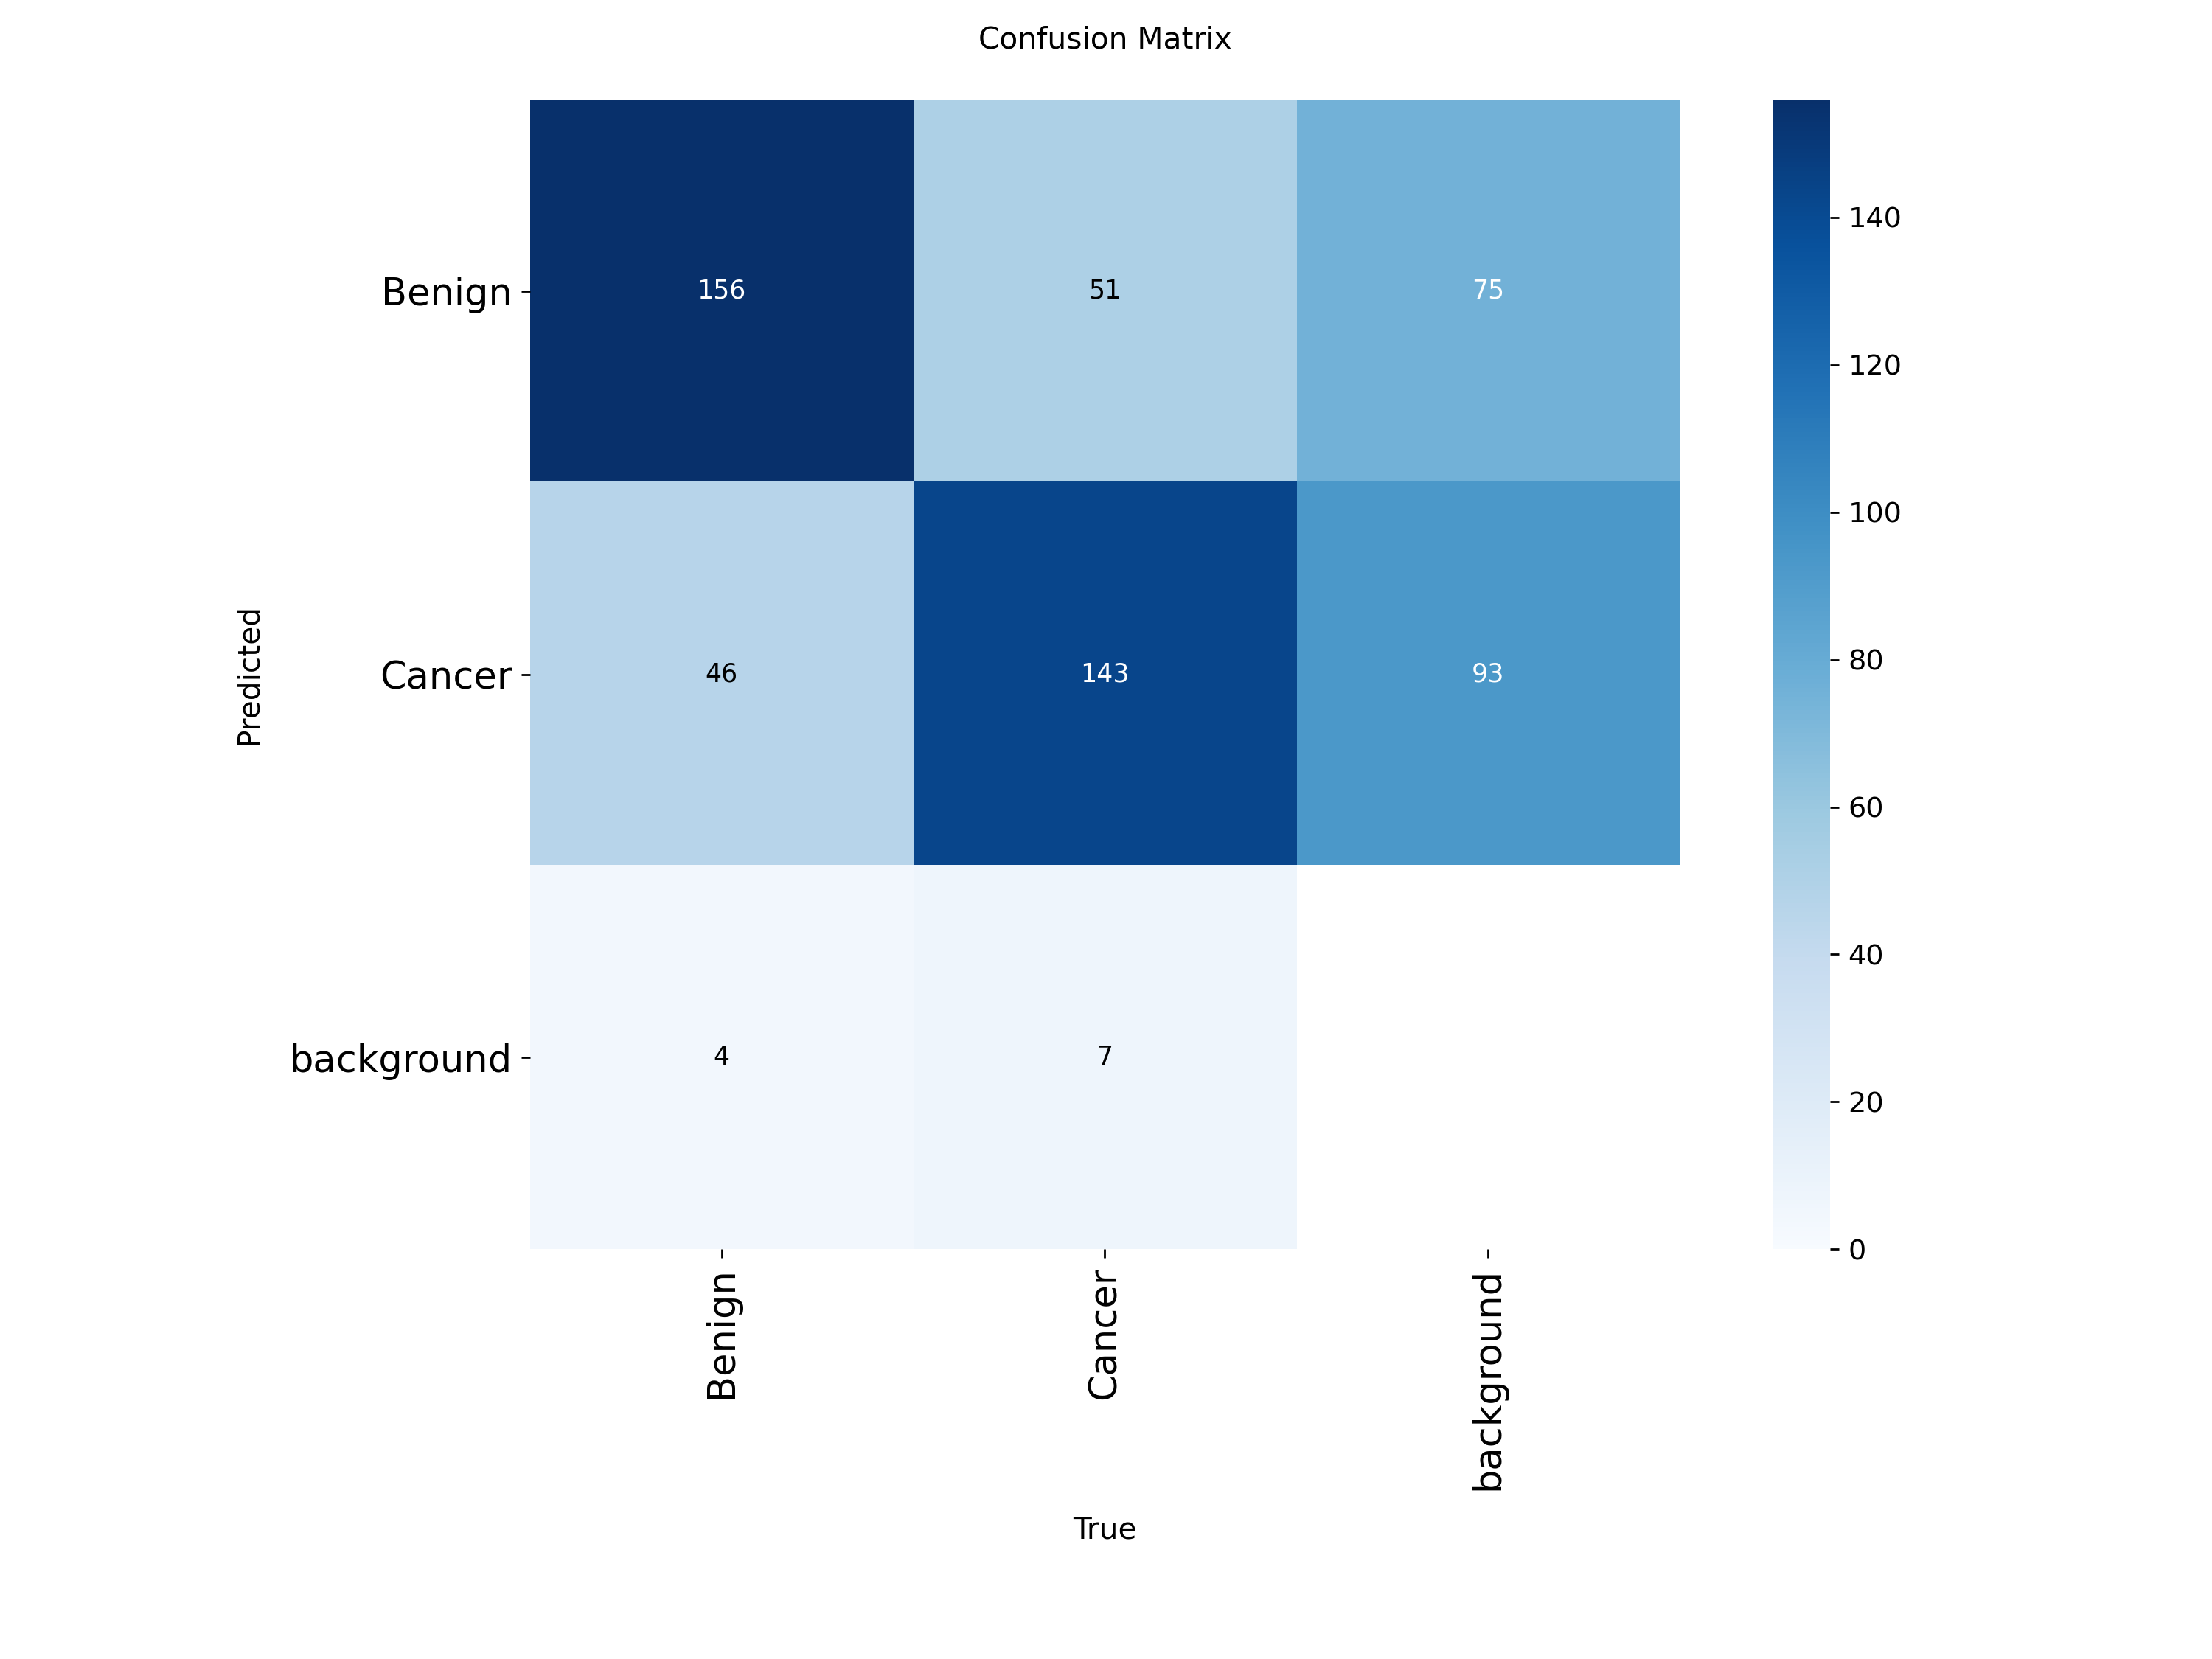

In [ ]:
%cd {HOME}
Image(filename=f'{HOME}/runs/detect/yolo11_skin_cancer_project3/confusion_matrix.png', width=600)

/content


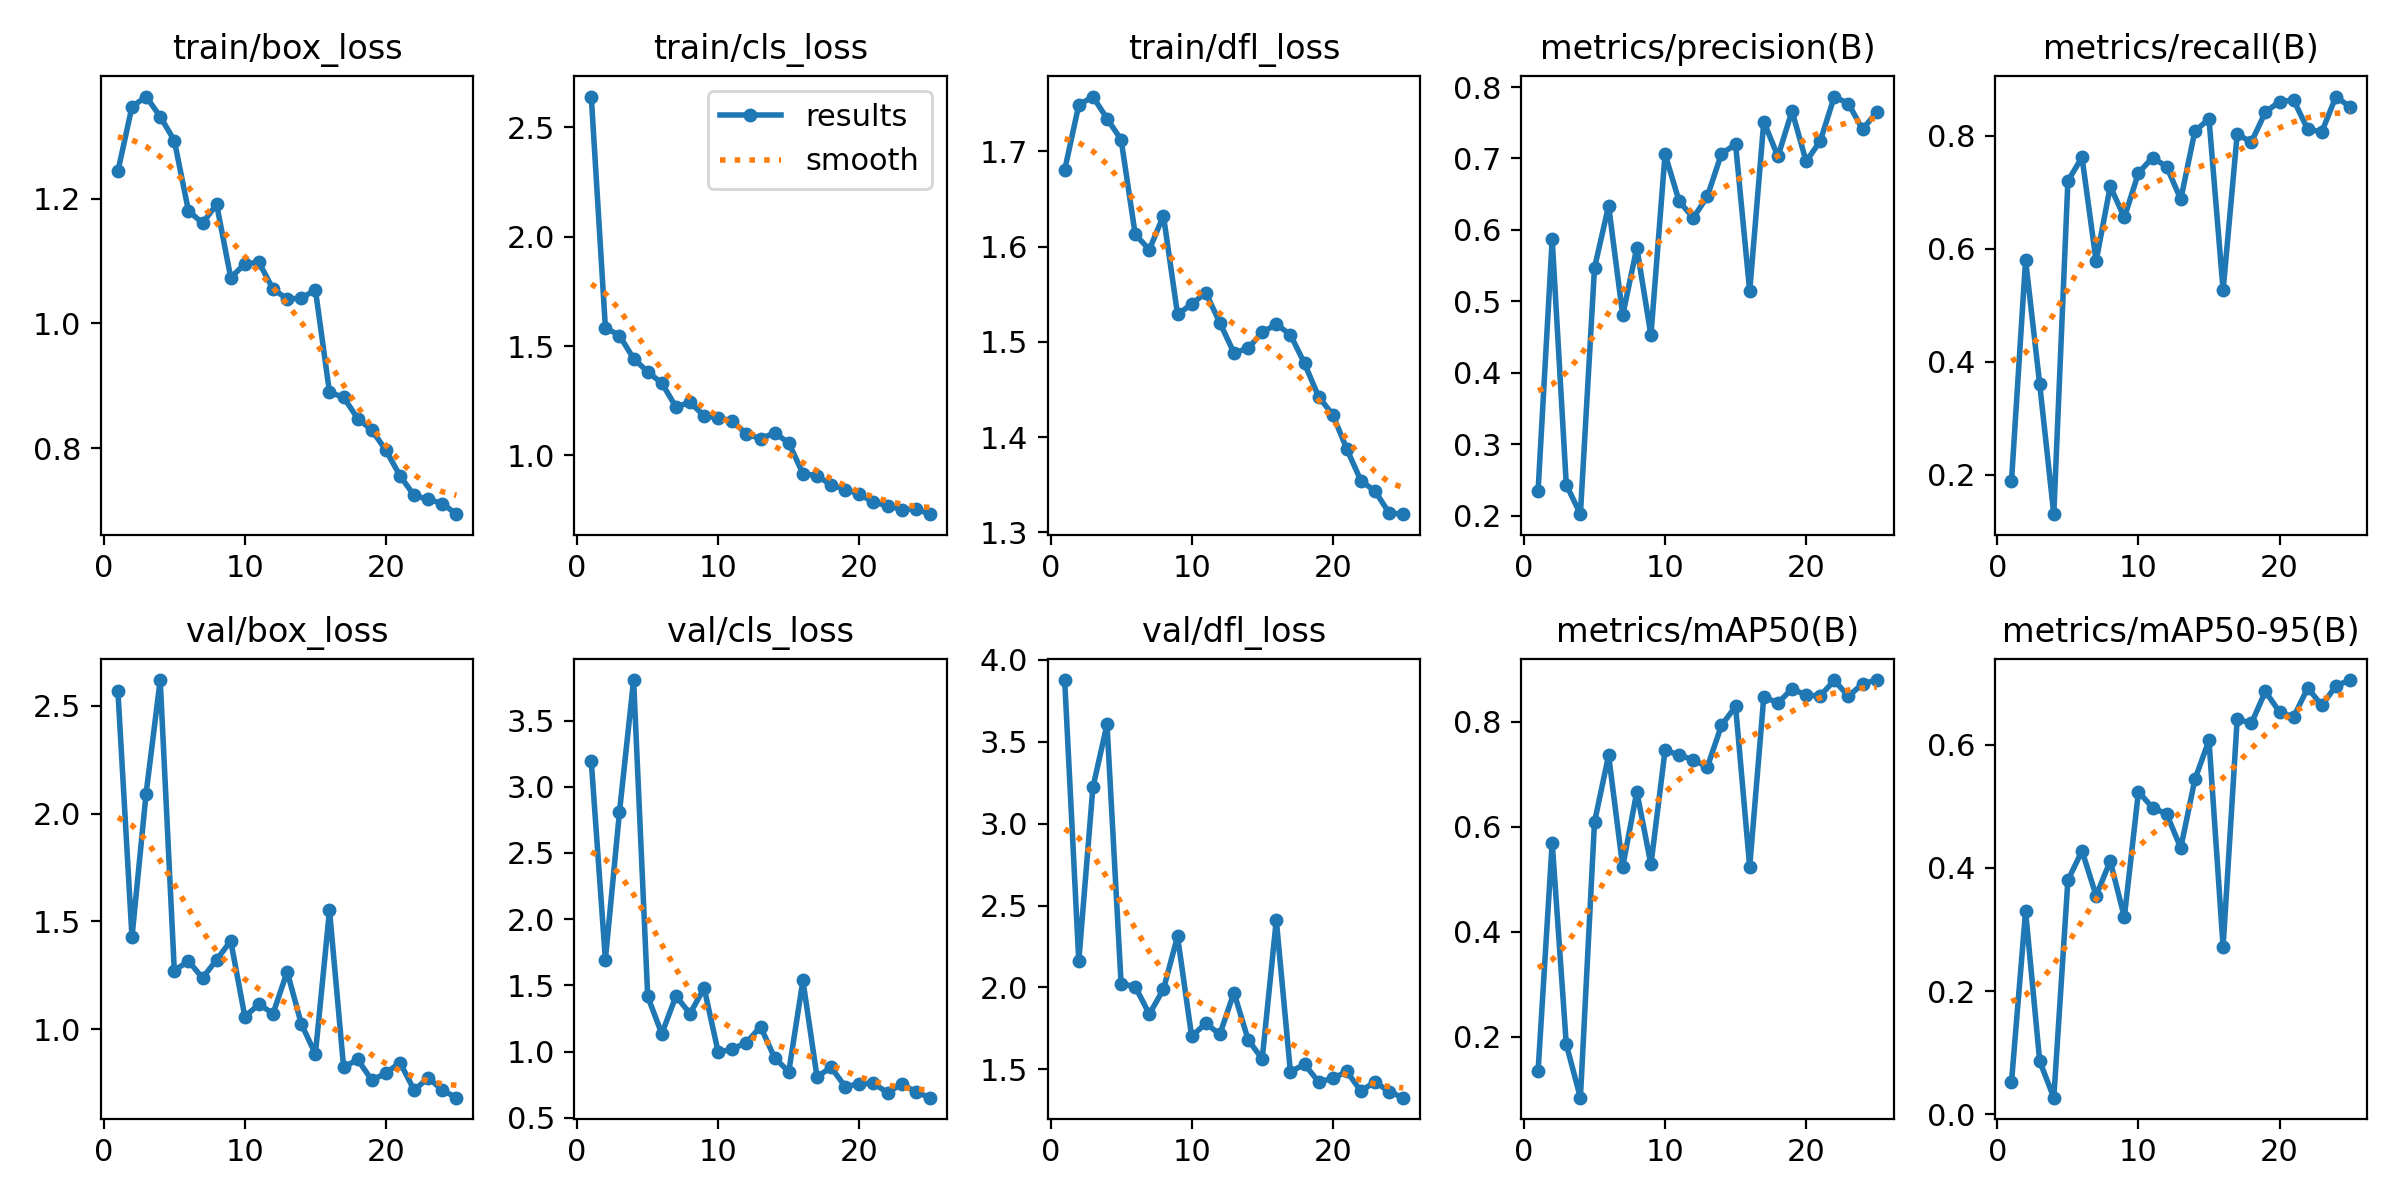

In [ ]:
%cd {HOME}
Image(filename=f'{HOME}/runs/detect/yolo11_skin_cancer_project3/results.png', width=600)

/content


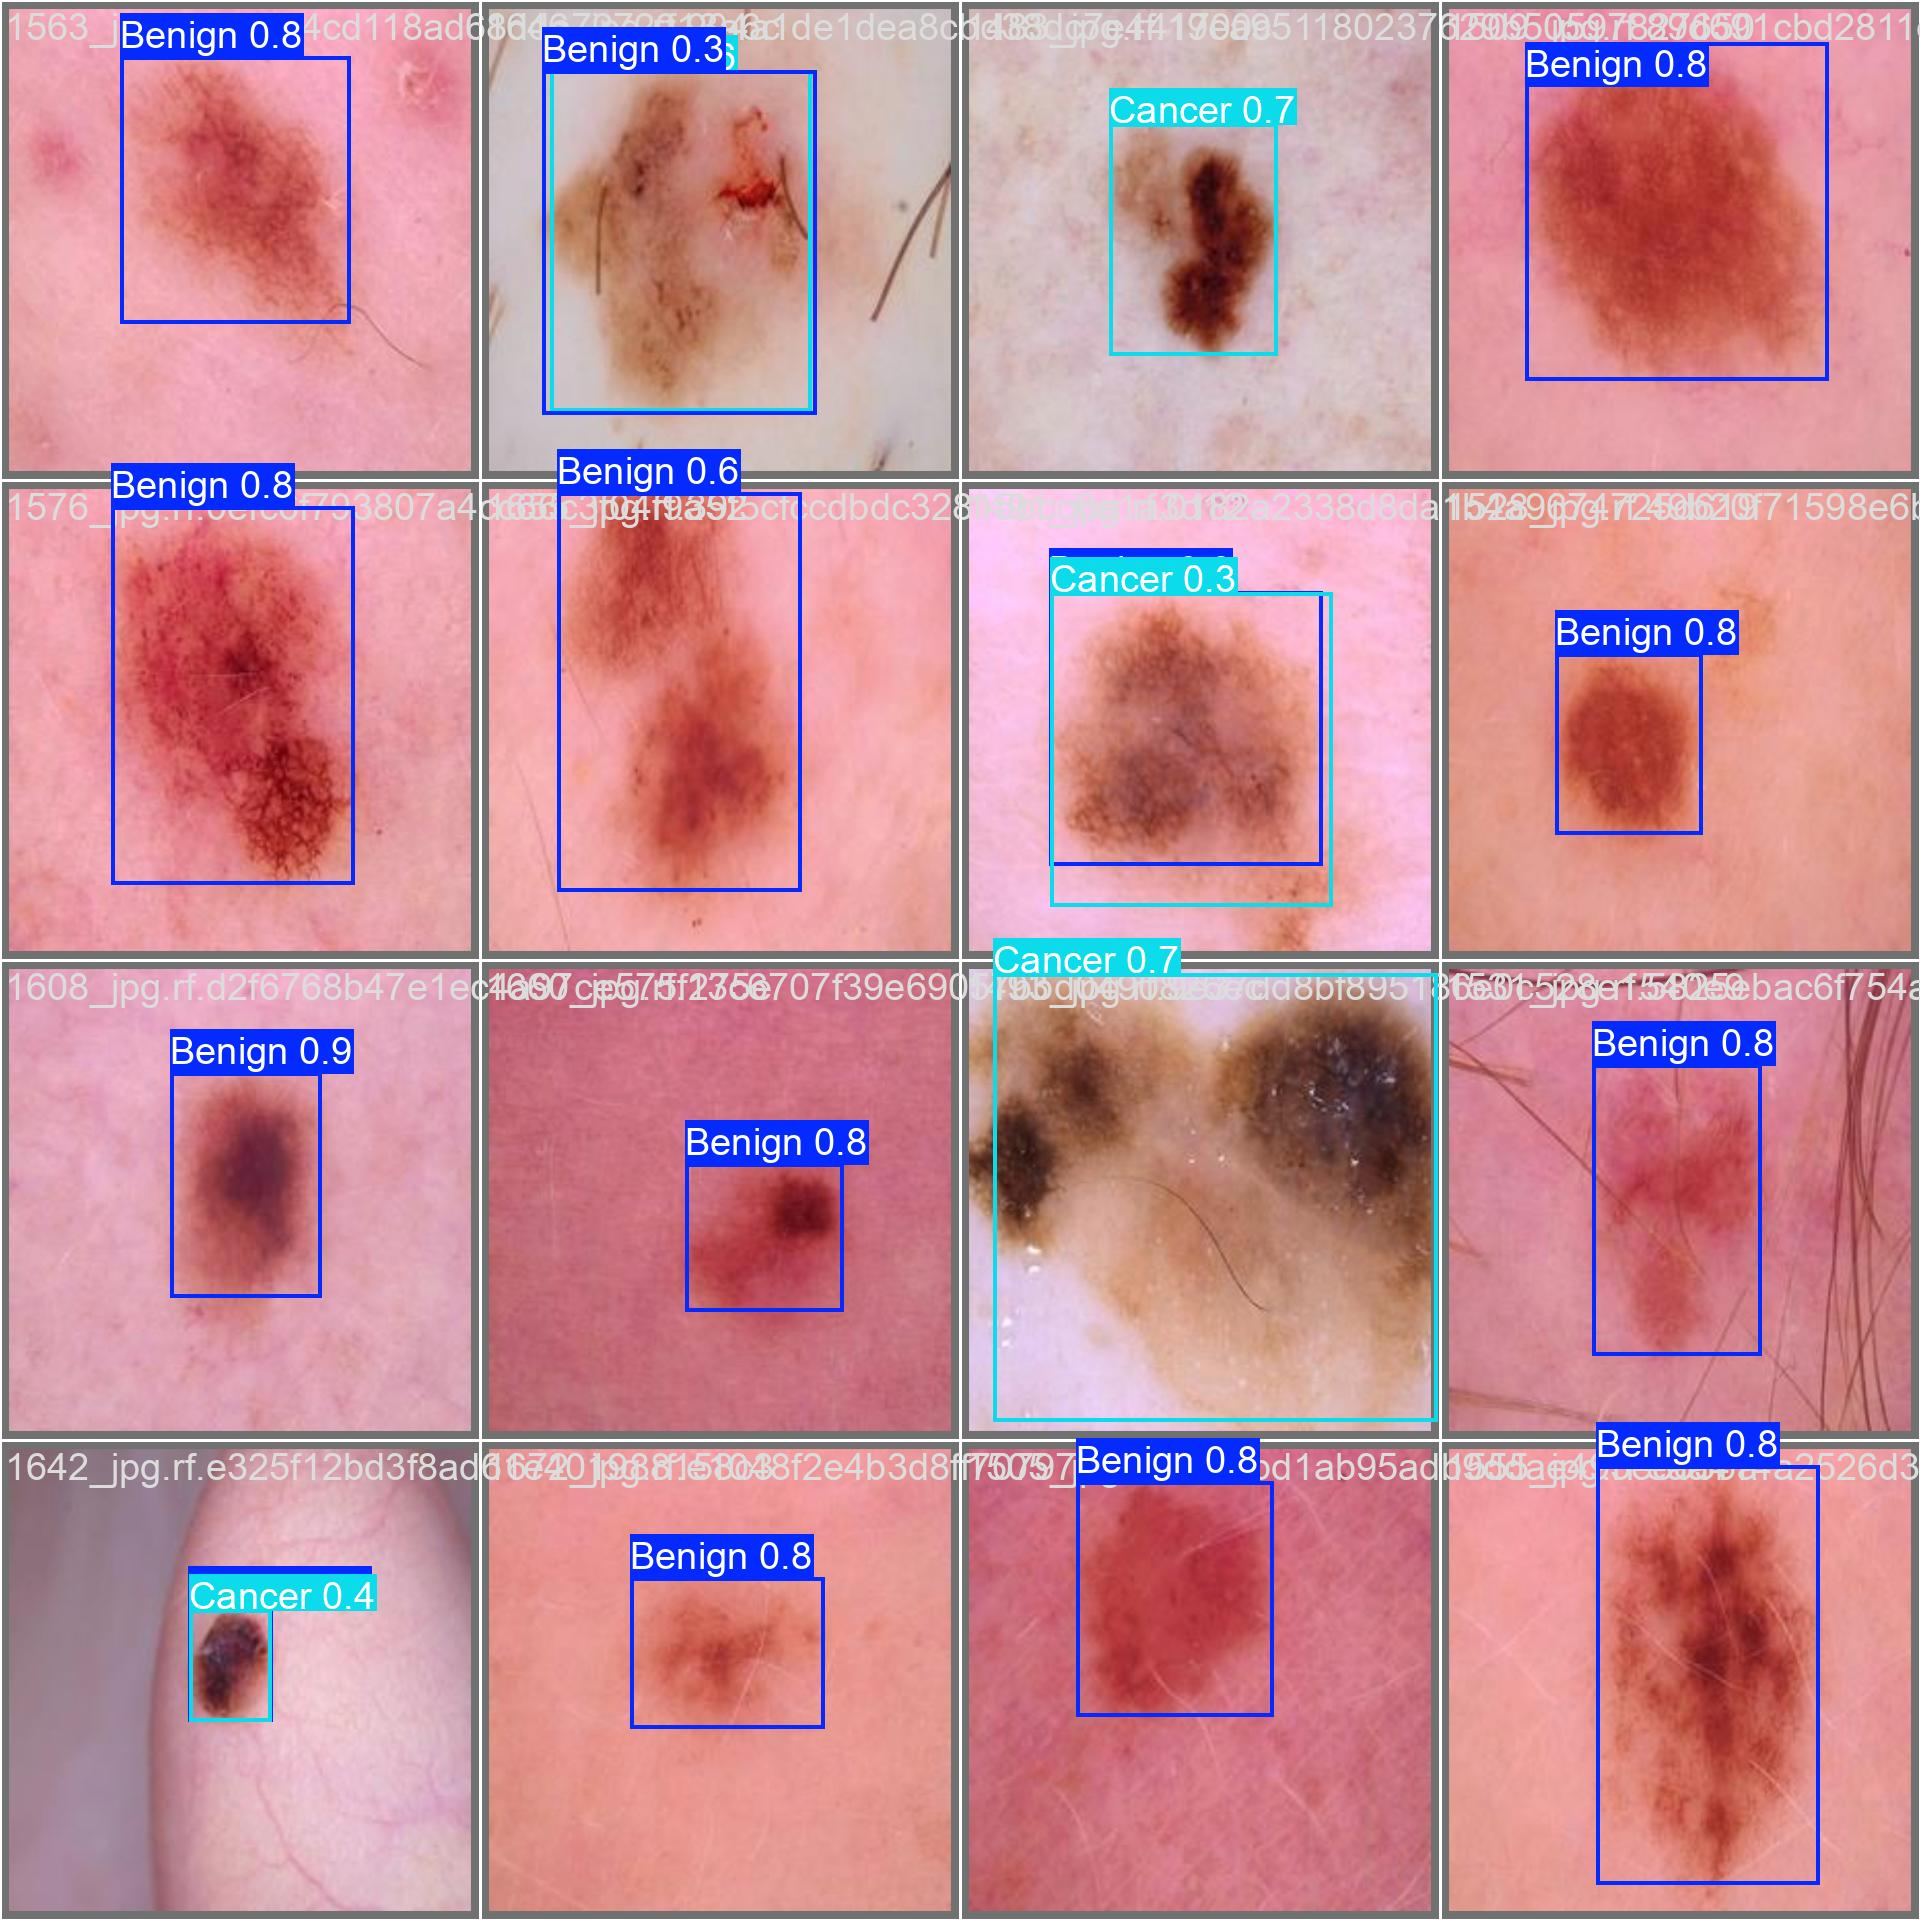

In [ ]:
%cd {HOME}
Image(filename=f'{HOME}/runs/detect/yolo11_skin_cancer_project3/val_batch0_pred.jpg', width=600)

In [ ]:
%cd {HOME}

!yolo task=detect mode=val model={HOME}/runs/detect/yolo11_skin_cancer_project3/weights/best.pt data={dataset.location}/data.yaml

/content
Ultralytics 8.4.36 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 101 layers, 9,413,574 parameters, 0 gradients, 21.3 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 293.5±160.4 MB/s, size: 7.6 KB)
val: Scanning /content/datasets/valid/labels.cache... 400 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 400/400 52.4Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 25/25 2.9it/s 8.5s
                   all        400        407      0.765       0.85      0.879      0.705
                Benign        200        206      0.788       0.83       0.91      0.748
                Cancer        200        201      0.742      0.871      0.849      0.662
Speed: 3.5ms preprocess, 13.6ms inference, 0.0ms loss, 1.0ms postprocess per image
Results saved to /content/runs/detect/val
💡 Learn more at https://docs.ultralytics.com/modes/val


In [ ]:
import pandas as pd
from ultralytics import YOLO # Ensure YOLO is imported for this cell

model_path = f'{HOME}/runs/detect/yolo11_skin_cancer_project3/weights/best.pt'
data_path = f'{HOME}/datasets/Skin-Cancer-1/data.yaml'

model = YOLO(model_path)

results = model.val(data=data_path)

names = list(results.names.values())

p_list = results.box.p.tolist()       # Precision listesi
r_list = results.box.r.tolist()       # Recall listesi
ap50_list = results.box.ap50.tolist() # mAP50 listesi
ap_list = results.box.ap.tolist()     # mAP50-95 listesi

metrics_data = []
for i, name in enumerate(names):
    metrics_data.append({
        "Class": name,
        "Precision": round(p_list[i], 3),
        "Recall": round(r_list[i], 3),
        "mAP@.5": round(ap50_list[i], 3),
        "mAP@.5:.95": round(ap_list[i], 3)
    })

all_stats = pd.DataFrame([{
    "Class": "all",
    "Precision": round(results.results_dict['metrics/precision(B)'], 3),
    "Recall": round(results.results_dict['metrics/recall(B)'], 3),
    "mAP@.5": round(results.results_dict['metrics/mAP50(B)'], 3),
    "mAP@.5:.95": round(results.results_dict['metrics/mAP50-95(B)'], 3)
}])

df_classes = pd.DataFrame(metrics_data)
final_table = pd.concat([all_stats, df_classes], ignore_index=True)

display(final_table)

Ultralytics 8.4.36 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 101 layers, 9,413,574 parameters, 0 gradients, 21.3 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 415.0±96.8 MB/s, size: 6.9 KB)
val: Scanning /content/datasets/valid/labels.cache... 400 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 400/400 69.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 25/25 2.9it/s 8.5s
                   all        400        407      0.765       0.85      0.879      0.705
                Benign        200        206      0.788       0.83       0.91      0.748
                Cancer        200        201      0.742      0.871      0.849      0.662
Speed: 2.7ms preprocess, 13.7ms inference, 0.0ms loss, 1.1ms postprocess per image
Results saved to /content/runs/detect/val2


,Class,Precision,Recall,mAP@.5,mAP@.5:.95
0,all,0.765,0.850,0.879,0.705
1,Benign,0.788,0.830,0.910,0.748
2,Cancer,0.742,0.871,0.849,0.662


In [ ]:
%cd {HOME}
!yolo task=detect mode=predict model={HOME}/runs/detect/yolo11_skin_cancer_project3/weights/best.pt conf=0.25 source={dataset.location}/test/images save=True

/content
Ultralytics 8.4.36 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 101 layers, 9,413,574 parameters, 0 gradients, 21.3 GFLOPs

image 1/199 /content/datasets/Skin-Cancer-1/test/images/0013_jpg.rf.8a3791653d30332040cb5f9b7203f234.jpg: 800x800 1 Cancer, 20.6ms
image 2/199 /content/datasets/Skin-Cancer-1/test/images/0014_jpg.rf.9ddcdd6dd784f88b6fecdfe2b8275999.jpg: 800x800 1 Benign, 20.6ms
image 3/199 /content/datasets/Skin-Cancer-1/test/images/0022_jpg.rf.1fb84d65733e49c1699f6a2a01a96258.jpg: 800x800 1 Cancer, 20.5ms
image 4/199 /content/datasets/Skin-Cancer-1/test/images/0026_jpg.rf.25cf54aaf5e74585aa228063e043d2eb.jpg: 800x800 3 Cancers, 20.5ms
image 5/199 /content/datasets/Skin-Cancer-1/test/images/0027_jpg.rf.1a9aaed8ac34b1c4480e66bcd75d6f71.jpg: 800x800 1 Cancer, 20.5ms
image 6/199 /content/datasets/Skin-Cancer-1/test/images/0028_jpg.rf.182f1063c261a13363c4c0c46e8bcddd.jpg: 800x800 1 Benign, 1 Cancer, 20.5ms
image 7/199 /content/datas

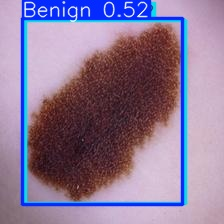

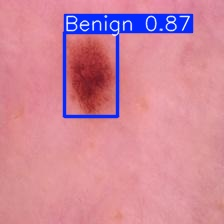

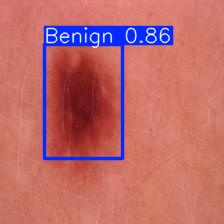

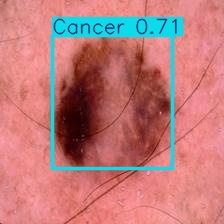

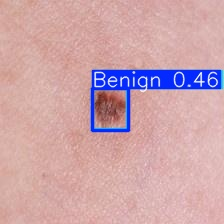

In [ ]:
import glob
from IPython.display import Image, display

base_path = '/content/runs/detect/'

subfolders = [os.path.join(base_path, d) for d in os.listdir(base_path)
              if os.path.isdir(os.path.join(base_path, d)) and d.startswith('predict')]

latest_folder = max(subfolders, key=os.path.getmtime)

image_paths = glob.glob(f'{latest_folder}/*.jpg')[:5]

for image_path in image_paths:
    display(Image(filename=image_path, width=600))
    print("\n")